# Homework 2 — Part 2: Single-stock risk report

Parameterized template. Papermill injects values after the tagged **parameters** cell. Risk metrics use **adjusted close** and **daily log returns**.


In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")


In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy of the course database
volatility_window = 20


In [3]:
# Parameters
ticker = "MSFT"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/lisuge/Developer/UCB-pre-MFE/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Suge_Li/data/data.db"
volatility_window = 20


## 2.2 Load cleaned prices


In [4]:
database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(
        f"Working database not found at {database}. "
        "Run 01_data_cleaning.ipynb first to create ohlc_hw_cleaned."
    )
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError("start_date must be on or before end_date.")
if not isinstance(volatility_window, int) or isinstance(volatility_window, bool) or volatility_window < 2:
    raise ValueError("volatility_window must be an integer >= 2.")

query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""
from contextlib import closing
with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as conn:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    if "ohlc_hw_cleaned" not in tables:
        raise FileNotFoundError("ohlc_hw_cleaned is missing. Run 01_data_cleaning.ipynb first.")
    df = pd.read_sql_query(
        query, conn, params=(ticker, start_date, end_date), parse_dates=["ts"], index_col="ts"
    )

n_obs = len(df)
actual_start = df.index.min() if n_obs else pd.NaT
actual_end = df.index.max() if n_obs else pd.NaT
print(f"{ticker} from {start_date} to {end_date}: {n_obs} trading days")
if n_obs:
    print(f"Actual first/last observation: {actual_start.date()} → {actual_end.date()}")
    display(df.head())
    display(df.tail())
min_prices = volatility_window + 1  # 20 returns require 21 prices
if n_obs < min_prices:
    raise ValueError(
        f"{ticker}: insufficient history for {volatility_window} returns "
        f"(need at least {min_prices} prices; got {n_obs} between {start_date} and {end_date})."
    )


MSFT from 2024-06-01 to 2024-11-30: 97 trading days
Actual first/last observation: 2024-06-03 → 2024-10-18


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,415.53,416.43,408.92,413.52,412.78,17484675
2024-06-04,412.43,416.44,409.68,416.07,415.32,14348917
2024-06-05,417.81,424.08,416.30,424.01,423.25,16988038
2024-06-06,424.01,425.31,420.58,424.52,423.76,14861251
2024-06-07,426.20,426.28,423.00,423.85,423.09,13621650


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,417.77,424.04,417.52,419.14,419.14,16653100
2024-10-15,422.18,422.48,415.26,418.74,418.74,18900201
2024-10-16,415.17,416.36,410.48,416.12,416.12,15508932
2024-10-17,422.36,422.50,415.59,416.72,416.72,14820004
2024-10-18,417.14,419.65,416.26,418.16,418.16,15820564


## 2.3 Risk metrics

`calculate_returns` returns **log** returns for this homework. Part 1's simple raw-close returns are a different diagnostic.


In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    Parameters
    ----------
    prices:
        Sorted positive price series (adjusted close for this report).

    Returns
    -------
    pd.Series
        ``log(price / previous_price)``. The first observation is missing.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility.

    Uses the sample standard deviation of daily log returns times ``sqrt(252)``.
    Warm-up dates with a partial window remain missing (not filled with zero).
    """
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    The series can recover toward zero. Summary maximum drawdown is
    ``drawdown.min()``; a running worst path would be ``drawdown.cummin()``.
    """
    return (prices - prices.cummax()) / prices.cummax()


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio.

    Course approximation: ``(mean_return * 252 - rf) / (std_return * sqrt(252))``
    with a 2% annual risk-free rate. Returns ``NaN`` when volatility is zero
    or fewer than two nonmissing returns are available.
    """
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * 252 - risk_free_rate) / (sigma * np.sqrt(252))


def quality_flags(frame: pd.DataFrame) -> pd.DataFrame:
    """Flag remaining problems in the cleaned extract."""
    price_cols = ["open", "high", "low", "close", "adj_close"]
    flags = pd.DataFrame(index=frame.index)
    flags["missing_or_nonfinite"] = ~np.isfinite(frame[price_cols + ["volume"]]).all(axis=1)
    flags["nonpositive_price"] = frame[price_cols].le(0).any(axis=1)
    flags["ohlc_bounds"] = (
        frame["high"].lt(frame[["open", "close"]].max(axis=1))
        | frame["low"].gt(frame[["open", "close"]].min(axis=1))
        | frame["high"].lt(frame["low"])
    )
    flags["negative_volume"] = frame["volume"].lt(0)
    flags["duplicate_date"] = frame.index.duplicated(keep=False)
    return flags


quality = quality_flags(df)
display(quality.sum())
data_quality_ok = bool(not quality.any().any())
if not data_quality_ok:
    raise ValueError("Data quality checks failed: " + str(quality.sum().to_dict()))

df = df.sort_index()
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"], window=volatility_window)
df["sma_50"] = df["adj_close"].rolling(50).mean()
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
metric_returns = df["log_return"].dropna()
assert df["volatility"].iloc[:volatility_window].isna().all()
print("Log-return count:", len(metric_returns), "| first/last adj_close:",
      float(df["adj_close"].iloc[0]), float(df["adj_close"].iloc[-1]))
sharpe_preview = calculate_sharpe_ratio(metric_returns)
print(f"Sharpe ratio: {'N/A' if pd.isna(sharpe_preview) else f'{sharpe_preview:.2f}'}")
print(f"Maximum drawdown: {df['drawdown'].min():.2%}")
display(df[["adj_close", "log_return", "volatility", "drawdown"]].head())
display(df[["adj_close", "log_return", "volatility", "drawdown"]].tail())


missing_or_nonfinite    0
nonpositive_price       0
ohlc_bounds             0
negative_volume         0
duplicate_date          0
dtype: int64

Log-return count: 96 | first/last adj_close: 412.78 418.16
Sharpe ratio: 0.07
Maximum drawdown: -15.49%


,adj_close,log_return,volatility,drawdown
ts,,,,
2024-06-03,412.78,NaN,NaN,0.000000
2024-06-04,415.32,0.006135,NaN,0.000000
2024-06-05,423.25,0.018914,NaN,0.000000
2024-06-06,423.76,0.001204,NaN,0.000000
2024-06-07,423.09,-0.001582,NaN,-0.001581


,adj_close,log_return,volatility,drawdown
ts,,,,
2024-10-14,419.14,0.006751,0.157876,-0.101945
2024-10-15,418.74,-0.000955,0.153223,-0.102803
2024-10-16,416.12,-0.006277,0.151159,-0.108416
2024-10-17,416.72,0.001441,0.132539,-0.107131
2024-10-18,418.16,0.003450,0.132650,-0.104045


## 2.4 Visualization


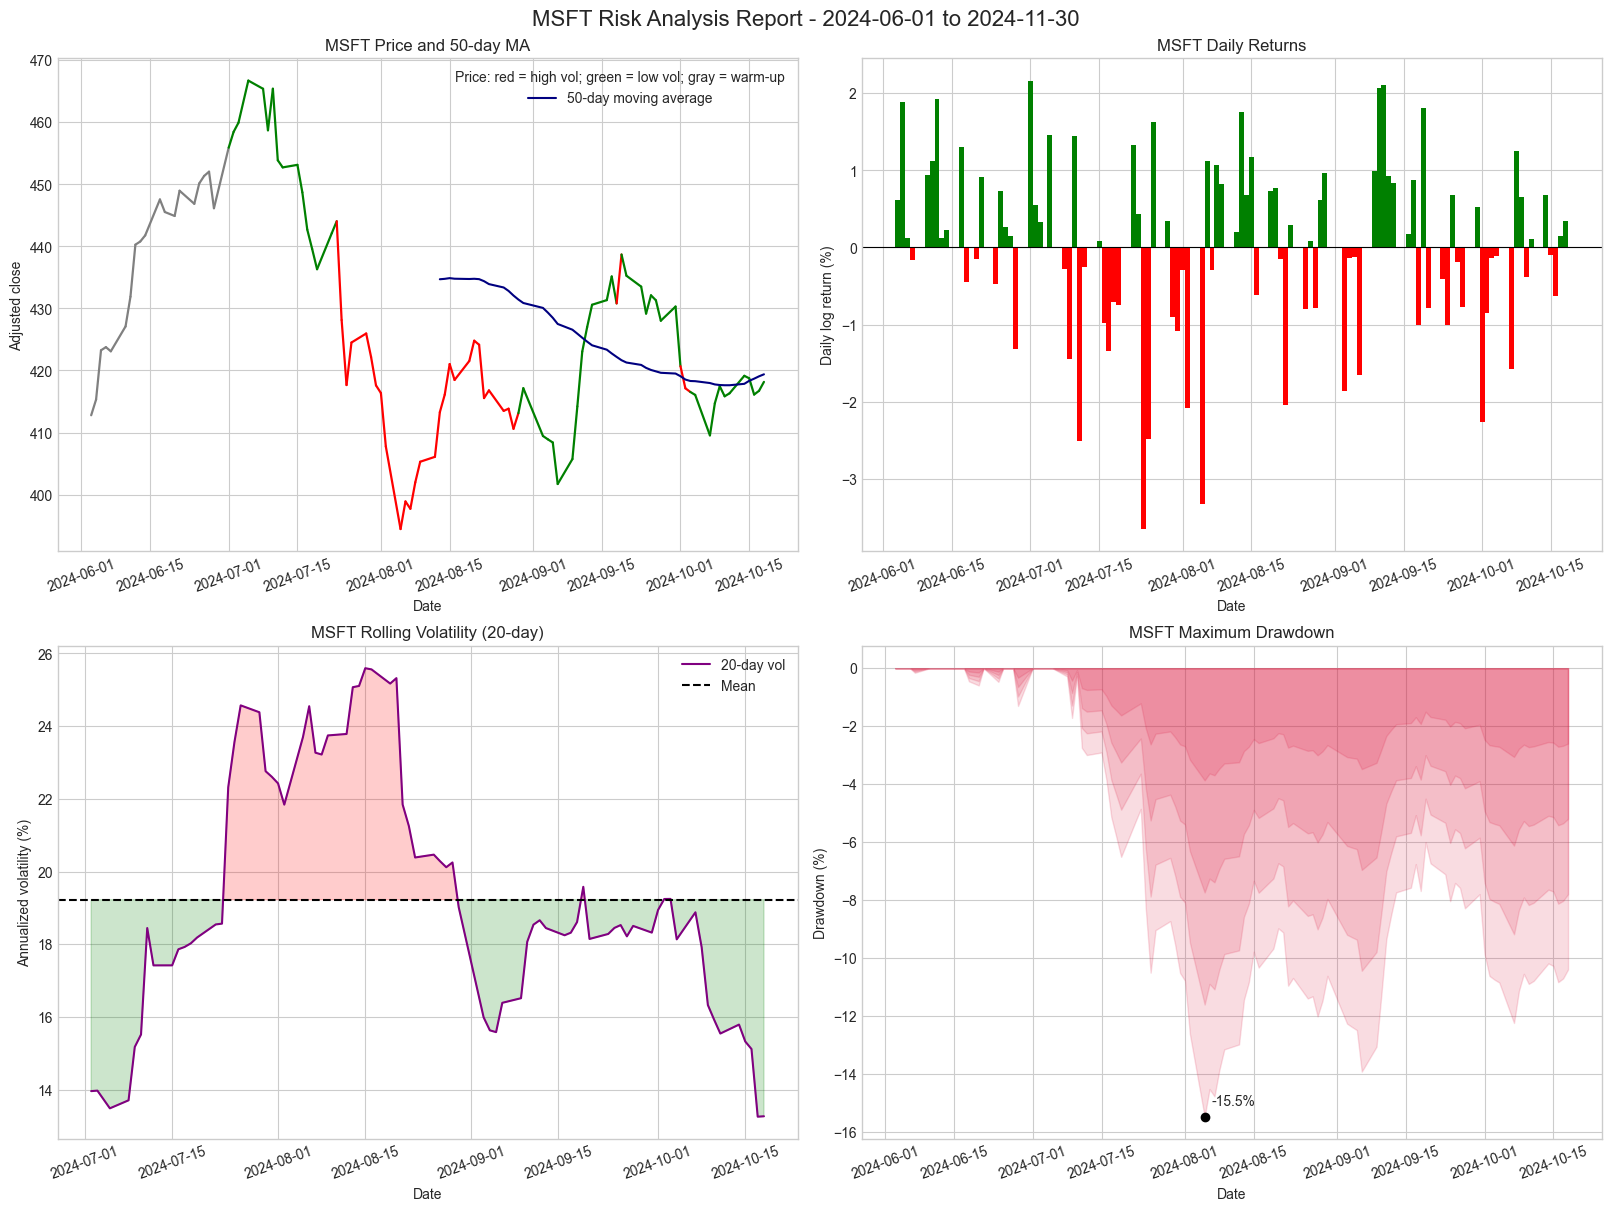

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=16)

mean_volatility = df["volatility"].mean()
for i in range(1, len(df)):
    vol = df["volatility"].iloc[i]
    if pd.isna(vol):
        color = "gray"
    elif vol > mean_volatility:
        color = "red"
    else:
        color = "green"  # equal-to-mean is green
    axes[0, 0].plot(df.index[i - 1:i + 1], df["adj_close"].iloc[i - 1:i + 1], color=color, linewidth=1.6)
if df["sma_50"].notna().any():
    axes[0, 0].plot(df.index, df["sma_50"], color="navy", label="50-day moving average")
else:
    axes[0, 0].text(
        0.02, 0.95,
        "50-day MA unavailable: fewer than 50 prices in this window.",
        transform=axes[0, 0].transAxes, va="top",
    )
axes[0, 0].set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close")
axes[0, 0].legend(title="Price: red = high vol; green = low vol; gray = warm-up")

observed_returns = df["log_return"].dropna()
bar_colors = np.where(observed_returns.ge(0), "green", "red")
axes[0, 1].bar(observed_returns.index, observed_returns * 100, width=1, color=bar_colors)
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set(title=f"{ticker} Daily Returns", ylabel="Daily log return (%)")

vol_pct = df["volatility"] * 100
axes[1, 0].plot(df.index, vol_pct, color="purple", label="20-day vol")
if pd.notna(mean_volatility):
    axes[1, 0].axhline(mean_volatility * 100, color="black", linestyle="--", label="Mean")
    axes[1, 0].fill_between(
        df.index, vol_pct, mean_volatility * 100,
        where=df["volatility"] > mean_volatility, color="red", alpha=0.2, interpolate=True,
    )
    axes[1, 0].fill_between(
        df.index, vol_pct, mean_volatility * 100,
        where=df["volatility"] <= mean_volatility, color="green", alpha=0.2, interpolate=True,
    )
axes[1, 0].set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility (%)")
axes[1, 0].legend()

drawdown_pct = df["drawdown"] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    axes[1, 1].fill_between(df.index, drawdown_pct * fraction, 0, color="crimson", alpha=0.15)
worst_date = df["drawdown"].idxmin()
axes[1, 1].scatter([worst_date], [drawdown_pct.loc[worst_date]], color="black", zorder=3)
axes[1, 1].annotate(
    f"{drawdown_pct.loc[worst_date]:.1f}%",
    (worst_date, drawdown_pct.loc[worst_date]),
    xytext=(5, 8), textcoords="offset points",
)
axes[1, 1].set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown (%)")

for ax in axes.flat:
    ax.set_xlabel("Date")
    ax.grid(True)
    ax.tick_params(axis="x", labelrotation=20)
plt.show()


## 2.5 Summary statistics

Fractions are kept for calculation and CSV export. Percent formatting is display-only.


In [7]:
n = len(metric_returns)
total_return = float(df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1)
if n == 0:
    annualized_return = np.nan
    annualized_volatility = np.nan
else:
    annualized_return = float(np.exp(metric_returns.sum() * 252 / n) - 1)
    annualized_volatility = float(metric_returns.std() * np.sqrt(252))
sharpe_ratio = calculate_sharpe_ratio(metric_returns)
up = metric_returns.loc[metric_returns > 0]
down = metric_returns.loc[metric_returns < 0]
avg_up = float(up.mean()) if len(up) else np.nan
avg_down = float(down.mean()) if len(down) else np.nan
positive_days = float(metric_returns.gt(0).mean()) if n else np.nan

stats = {
    "ticker": ticker,
    "start_date": start_date,
    "end_date": end_date,
    "actual_start": str(actual_start.date()),
    "actual_end": str(actual_end.date()),
    "trading_days": int(n_obs),
    "total_return": total_return,
    "total_return_pct": total_return * 100,
    "annualized_return": annualized_return,
    "annualized_volatility": annualized_volatility,
    "avg_volatility": float(df["volatility"].mean()) if df["volatility"].notna().any() else np.nan,
    "max_drawdown": float(df["drawdown"].min()),
    "max_drawdown_pct": float(df["drawdown"].min()) * 100,
    "sharpe_ratio": float(sharpe_ratio) if pd.notna(sharpe_ratio) else np.nan,
    "avg_daily_return": float(metric_returns.mean()) if n else np.nan,
    "positive_days": positive_days,
    "avg_up_day": avg_up,
    "avg_down_day": avg_down,
    "data_quality_ok": data_quality_ok,
}

def _fmt(metric: str, value) -> str:
    if pd.isna(value):
        return "N/A"
    if metric == "Sharpe Ratio":
        return f"{value:.2f}"
    if metric == "Positive Days":
        return f"{value:.1%}"
    signed = metric in {"Total Return", "Annualized Return", "Maximum Drawdown", "Best Day", "Worst Day",
                        "Average Up Day", "Average Down Day"}
    if signed:
        return f"{value:+.2%}" if metric != "Maximum Drawdown" and metric != "Average Down Day" and metric != "Worst Day" else f"{value:.2%}"
    return f"{value:.2%}"


summary_metrics = pd.Series({
    "Total Return": stats["total_return"],
    "Annualized Return": stats["annualized_return"],
    "Annualized Volatility": stats["annualized_volatility"],
    "Sharpe Ratio": stats["sharpe_ratio"],
    "Maximum Drawdown": stats["max_drawdown"],
    "Best Day": float(metric_returns.max()) if n else np.nan,
    "Worst Day": float(metric_returns.min()) if n else np.nan,
    "Positive Days": stats["positive_days"],
    "Average Up Day": stats["avg_up_day"],
    "Average Down Day": stats["avg_down_day"],
}, name="Value")

display_summary = pd.DataFrame({
    "Metric": summary_metrics.index,
    "Value": [_fmt(metric, value) for metric, value in summary_metrics.items()],
})
print(f"{ticker} from {start_date} to {end_date}: {n_obs} trading days "
      f"(actual {stats['actual_start']} to {stats['actual_end']})")
display(display_summary)

serializable_stats = {
    key: (value.item() if isinstance(value, np.generic) else value) for key, value in stats.items()
}
sb.glue("ticker", ticker)
sb.glue("start_date", start_date)
sb.glue("end_date", end_date)
sb.glue("trading_days", stats["trading_days"])
sb.glue("total_return_pct", stats["total_return_pct"])
sb.glue("avg_volatility", stats["avg_volatility"])
sb.glue("max_drawdown_pct", stats["max_drawdown_pct"])
sb.glue("data_quality_ok", data_quality_ok)
sb.glue("sharpe_ratio", stats["sharpe_ratio"])
sb.glue("avg_daily_return", stats["avg_daily_return"])
sb.glue("total_return", stats["total_return"])
sb.glue("max_drawdown", stats["max_drawdown"])
sb.glue("actual_start", stats["actual_start"])
sb.glue("actual_end", stats["actual_end"])
sb.glue("stats", serializable_stats)
sb.glue("prices", df, encoder="pandas")
sb.glue("analysis_plot", fig, encoder="display", display=False)
print("Results exported via scrapbook.")


MSFT from 2024-06-01 to 2024-11-30: 97 trading days (actual 2024-06-03 to 2024-10-18)


,Metric,Value
0,Total Return,+1.30%
1,Annualized Return,+3.46%
2,Annualized Volatility,18.74%
3,Sharpe Ratio,0.07
4,Maximum Drawdown,-15.49%
5,Best Day,+2.16%
6,Worst Day,-3.65%
7,Positive Days,54.2%
8,Average Up Day,+0.86%
9,Average Down Day,-0.98%


Results exported via scrapbook.
